# Production run — RMSE, R², IA and MNB per administrative unit

Scores the calibrated production run (SIMPLACE and torchcrop, both on the
per-region calibrated crops) against the references the calibration was fitted
to, **on the basis it was fitted on**:

| Target | Reference | Correction | Years |
|---|---|---|---|
| Grain yield | CyBench, NUTS-2/3 | × (1 − 0.135) to dry matter | 2000–2021 |
| Emergence | CLMS `CPMCE` | −6.0 d (PEP725) | 2017–2024 |
| Harvest | CLMS `CPMCH` | +18.7 d (PEP725) | 2017–2024 |
| Emergence → harvest | CLMS | +24.7 d (the sum) | 2017–2024 |

A 10 km cell is assigned to the unit containing its centre and units are
equal-weight means of their cells; dates are averaged on the circle.

**Metrics.** Error is simulated − observed.

* **RMSE** in the target's unit.
* **R²**, the squared Pearson correlation, 0–1: the share of the observed
  variation the simulation tracks. It is blind to an offset and to a wrong
  amplitude, so read it beside RMSE and bias. (Not the coefficient of
  determination the calibration tables call `r2`, which goes negative under a
  bias.)
* **IA**, Willmott's index of agreement, 0–1: 1 is a perfect match. Unlike R²
  it also penalises an offset or a wrong amplitude.
* **MNB**, mean normalised bias `mean((S − O) / O)` in %. It is defined only for
  ratio-scale quantities (yield, season length). A day-of-year has no natural
  zero, so for **emergence and harvest the third map is the bias in days**.

Each unit is scored over its own seasons, and needs at least
`MIN_YEARS` of them. With CLMS's eight seasons that is a short series, so the
per-unit R² and IA are noisy; the pooled table at the end is the stable summary.

Only an observed-weather run can be scored year by year — a CMIP6 year is a
sample of that model's climate, not the observed season of the same number, and
`check_year_matched` refuses such a run.

## 0. Setup

In [1]:
import logging
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from cropmodelling4eu.evaluation import production as prod
from cropmodelling4eu.evaluation.fullrun import load_runs
from cropmodelling4eu.evaluation.plots import EUROPE_PROJECTION, country_choropleth, save
from cropmodelling4eu.evaluation.regions import load_admin_polygons
import colormaps as cmaps

from cropmodelling4eu.evaluation.style import SEQUENTIAL_CMAP, use_poster_style

logging.basicConfig(level=logging.WARNING, format="%(levelname)s %(name)s: %(message)s",
                    force=True)
# The TorchCrop poster's look: Segoe UI (Selawik fallback), black text and
# spines, SIMPLACE grey and TorchCrop teal (evaluation.style.use_poster_style).
PALETTE = use_poster_style()

#: Override with PRODUCTION_RUN_DIR / CALIBRATION_DIR in the environment.
RUN = prod.PRODUCTION_RUN_DIR
CALIBRATION = prod.CALIBRATION_DIR
prod.check_year_matched(RUN)

YEARS = (2000, 2024)
MIN_YEARS = prod.MIN_YEARS
OUT = Path(os.environ.get("PRODUCTION_EVAL_DIR", RUN / "evaluation"))
FIGURES, TABLES = OUT / "figures", OUT / "tables"
TABLES.mkdir(parents=True, exist_ok=True)

MODELS = {"simplace": "SIMPLACE", "torchcrop": "TorchCrop"}


def _limit(values: pd.Series, q: float = 0.95) -> float:
    """Symmetric colour limit: the q-quantile of |values|."""
    finite = values.replace([np.inf, -np.inf], np.nan).dropna()
    return float(finite.abs().quantile(q)) if len(finite) else 1.0

print(f"run         : {RUN}")
print(f"calibration : {CALIBRATION}")
print(f"outputs     : {OUT}")

run         : /data01/FDS/muduchuru/Data/SIMPLACE/cropmodelling4eu/runs/winter_wheat/calibrated/mswx
calibration : /data01/FDS/muduchuru/Data/SIMPLACE/cropmodelling4eu/winter_wheat_2000_2024_euval/calibration
outputs     : /data01/FDS/muduchuru/Data/SIMPLACE/cropmodelling4eu/runs/winter_wheat/calibrated/mswx/evaluation


## 1. Load the runs and the corrected references

In [2]:
runs = load_runs(RUN / "simplace" / "simplace_europe.parquet",
                 RUN / "torchcrop" / "torchcrop_europe.parquet", years=YEARS)
cell_to_adm = pd.read_parquet(CALIBRATION / "cell_to_adm.parquet")
countries = sorted(cell_to_adm["adm_country"].dropna().unique())
reference = prod.load_reference(countries, YEARS)
polygons = load_admin_polygons(countries)

paired = prod.pair_units(runs, reference, cell_to_adm, CALIBRATION)
pd.DataFrame({
    model: {
        "cell-seasons": len(frame),
        "cells": frame["SimplaceID"].nunique(),
        "years": f"{frame['year'].min()}-{frame['year'].max()}",
        "paired units": paired.loc[paired["model"] == model, "adm_id"].nunique(),
    }
    for model, frame in runs.items()
}).T

WARNING cropmodelling4eu.evaluation.torchcrop: 183 of 1711524 rows (0.01%) never reached maturity; their dates are NaN


WARNING cropmodelling4eu.evaluation.fullrun: simplace: 5332 of 1716679 rows (0.31%) carry a season shorter than 150 days -- the (0, 365] wrap in collect.to_run_schema, not a 3-day crop. Their durations are dropped; their dates are kept


,cell-seasons,cells,years,paired units
torchcrop,1711524,68685,2000-2024,843
simplace,1716679,68685,2000-2024,843


How many paired unit-years each target has, by the calibration split it fell
in. `unused` rows are units or years the calibration never saw: for yield they
are mostly units with no calibration region, for phenology the CyBench units
whose CLMS series was gated out of the calibration pool.

In [3]:
one_model = paired[paired["model"] == "simplace"]
pd.DataFrame({
    t.label: one_model.dropna(subset=[t.sim_col, t.obs_col])[f"split_{t.key}"].value_counts()
    for t in prod.TARGETS
}).fillna(0).astype(int).T

,test,train,unused,val
Grain yield,2197,12161,7,564
Emergence,1554,3591,0,666
Harvest,1554,3591,0,666
Emergence to harvest,1554,3591,0,666


## 2. Climatological means

Each unit's mean over **its own paired seasons**, the same unit-years on both
sides, so the bottom row is a climatological bias with no sampling difference
in it. The top row shares one colour scale (5th–95th percentile of all three
panels). Dates are circular means unwrapped about the domain mean, so the scale
has no seam at New Year: an emergence of DOY 370 is 5 January.

In [4]:
# Means: YlGnBu in 11 steps, lightest = lowest. Its own first quarter is
# near-white and vanishes against the map's land and sea (OKLab dE 5), so the
# ramp starts at 0.28, a pale green 10+ from both. Differences: NCL's
# BlueDarkOrange18 (colormaps package), teal = model low or early, brown = high
# or late.
from matplotlib.colors import ListedColormap

CLIM_CMAP = ListedColormap(plt.get_cmap("YlGnBu")(np.linspace(0.28, 1.0, 11)), name="YlGnBu_11")
DIFF_CMAP = cmaps.BlueDarkOrange18
climatology = prod.unit_climatology(paired, min_years=MIN_YEARS)
climatology.to_csv(TABLES / "unit_climatology.csv", index=False)


def climatology_maps(target: prod.Target):
    clim = climatology[climatology["target"] == target.key]
    observed = clim.drop_duplicates("adm_id").set_index("adm_id")["obs"]
    unit = "DOY" if target.circular else target.unit
    lo, hi = np.nanpercentile(np.r_[observed, clim["sim"]], [5, 95])
    fig, axes = plt.subplots(2, 3, figsize=(13.0, 9.6),
                             subplot_kw={"projection": EUROPE_PROJECTION})
    panels = [("Observed", observed),
              *[(label, clim[clim["model"] == m].set_index("adm_id")["sim"])
                for m, label in MODELS.items()]]
    for ax, (label, values) in zip(axes[0], panels):
        country_choropleth(polygons, values, key_col="adm_id", diverging=False,
                           cmap=CLIM_CMAP, vmin=lo, vmax=hi, linewidth=0.15,
                           title=label, cbar_label=f"{target.label} ({unit})", ax=ax)
    diff_unit = "days" if target.circular else target.unit
    limit = _limit(clim["diff"])
    axes[1, 0].set_visible(False)
    for ax, (model, label) in zip(axes[1, 1:], MODELS.items()):
        values = clim[clim["model"] == model].set_index("adm_id")["diff"]
        country_choropleth(polygons, values, key_col="adm_id", diverging=True, vmax=limit,
                           cmap=DIFF_CMAP, linewidth=0.15, title=f"{label} − observed",
                           cbar_label=f"Difference ({diff_unit})", ax=ax)
        ax.text(0.03, 0.03, f"median {values.median():+.2f}", transform=ax.transAxes,
                fontsize=10, color="black",
                bbox={"facecolor": PALETTE["surface"], "edgecolor": "none", "alpha": 0.85, "pad": 2})
    source = "dry-matter CyBench" if target.key == "yield" else "corrected CLMS"
    fig.suptitle(f"{target.label} — climatological mean per unit vs {source}", y=0.995)
    fig.tight_layout()
    save(fig, f"climatology_{target.key}", FIGURES)
    return fig

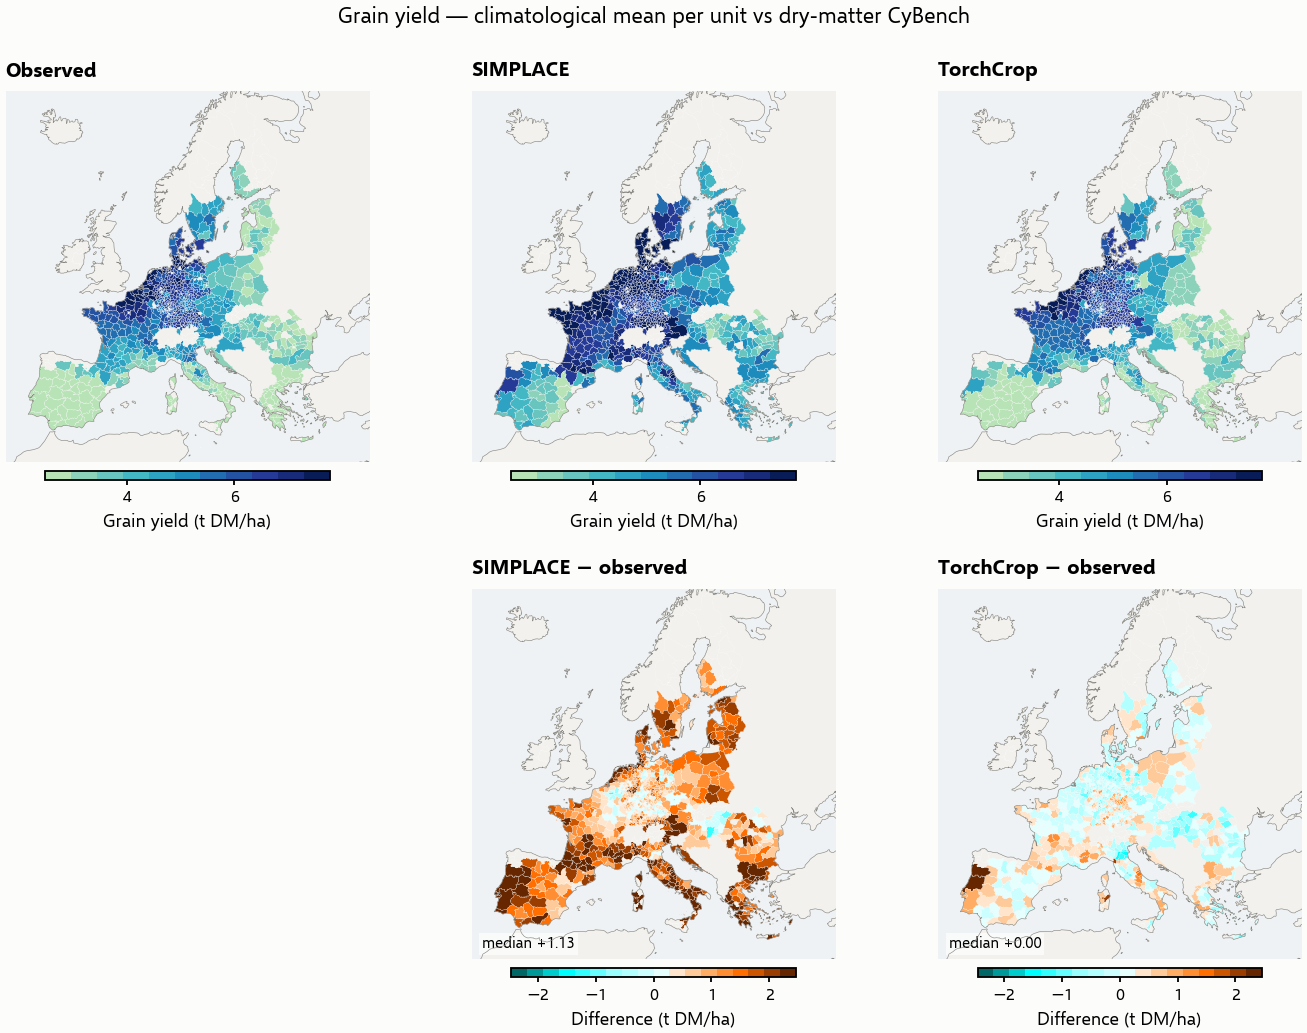

In [5]:
climatology_maps(next(t for t in prod.TARGETS if t.key == 'yield'));

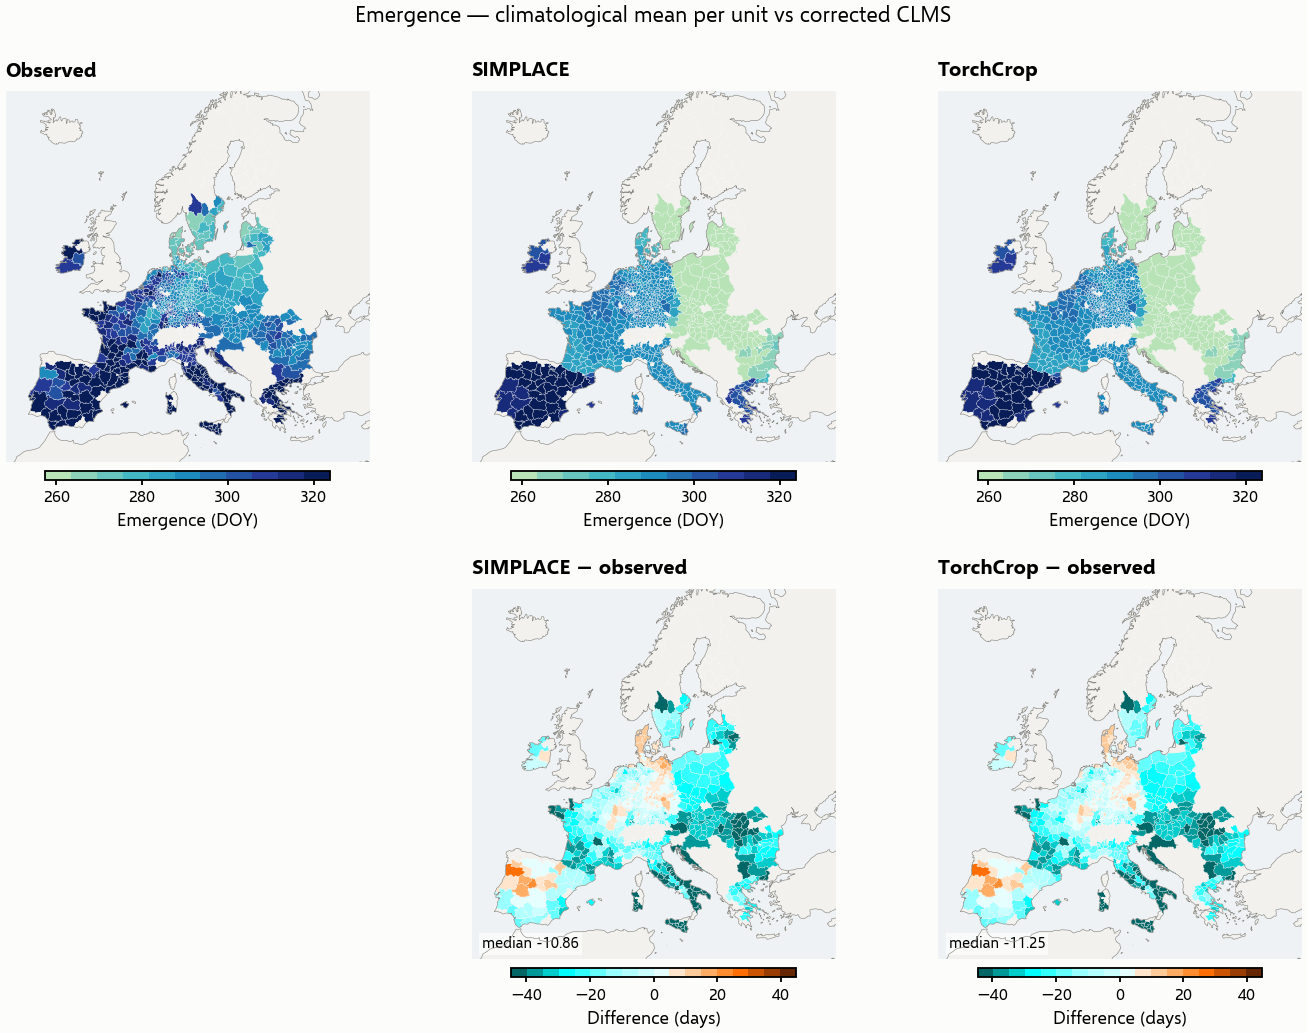

In [6]:
climatology_maps(next(t for t in prod.TARGETS if t.key == 'emergence'));

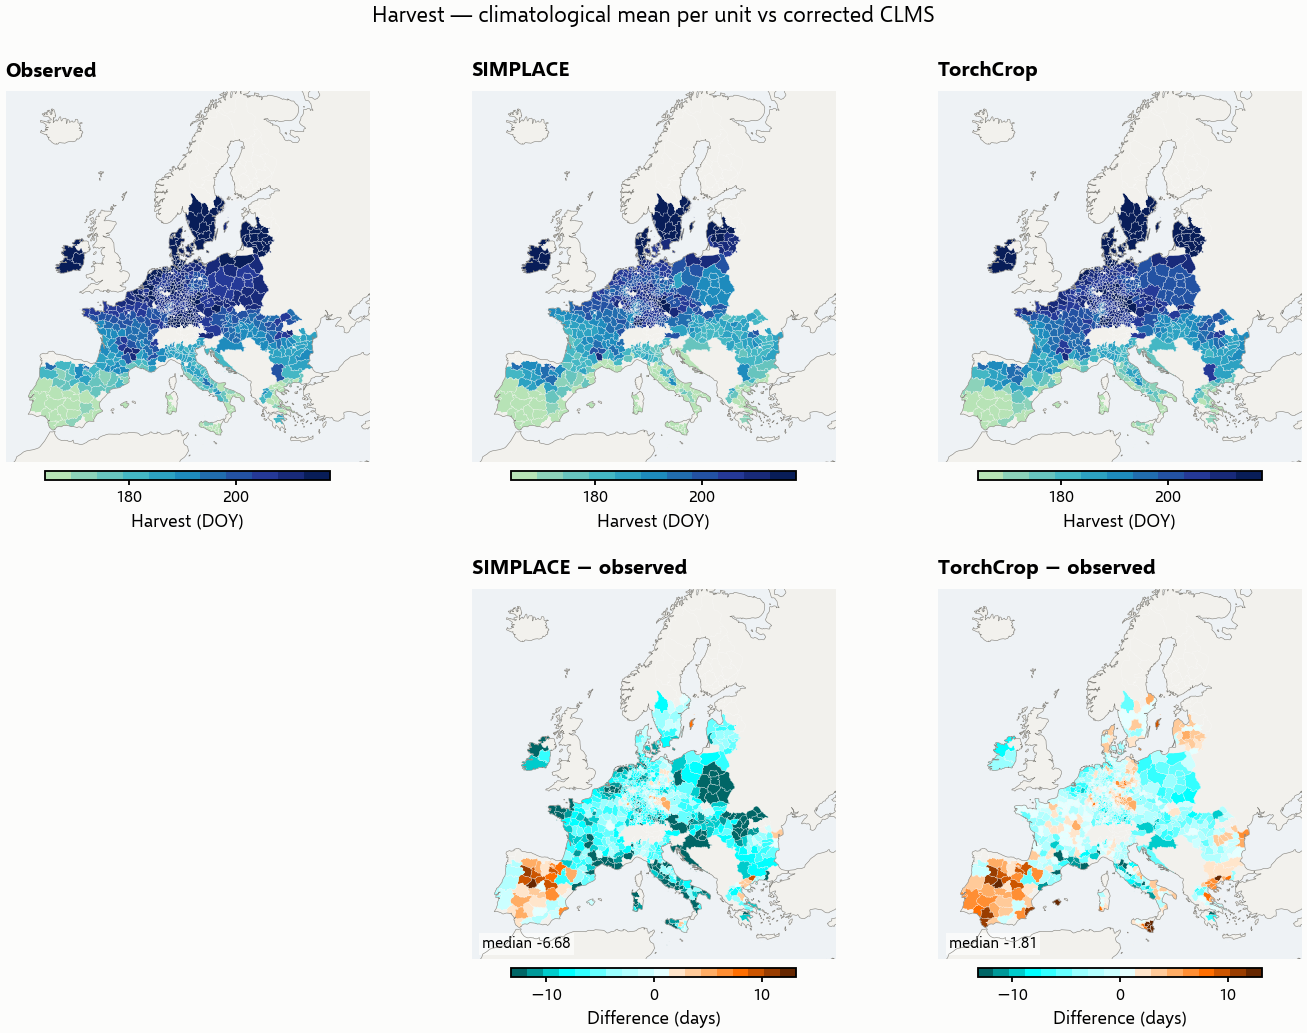

In [7]:
climatology_maps(next(t for t in prod.TARGETS if t.key == 'harvest'));

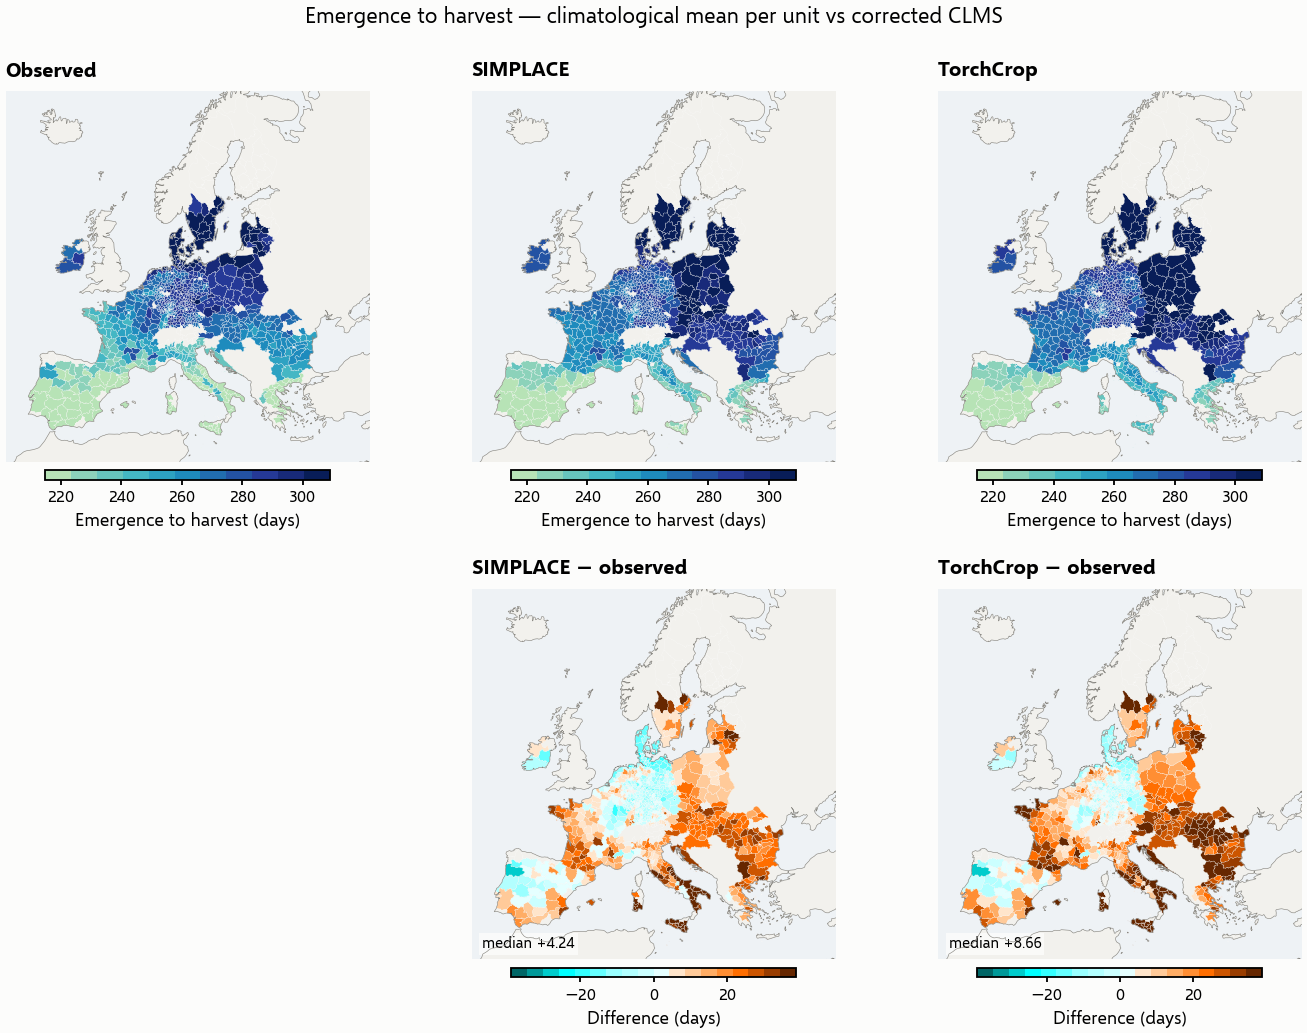

In [8]:
climatology_maps(next(t for t in prod.TARGETS if t.key == 'season_length'));

### Observed yield: market moisture → dry matter

CyBench reports grain at market moisture; both models simulate grain dry
matter. Every yield score in this notebook uses the **corrected** observation,
`CyBench × (1 − 0.135)`. The table puts the reported and corrected observations
side by side per country, then gives the climatological bias against each.

**Read the bias against the calibration's crops.** The crops this run uses
(`calibration/yield/crops`, fitted 2026-10-22) were fitted to the
*uncorrected* series: `calibration.prepare` did not apply the conversion, so
the fit targeted fresh weight. A model that matches that target sits
`0.135 / 0.865 ≈ +15.6 %` above dry matter. The *vs reported* column is
therefore the calibration's own residual, and the gap between the two columns
is the moisture basis, not model error. This holds until production runs on
the crops recalibrated against dry matter (`calibration_dm/`).

In [9]:
MOISTURE = prod.YIELD_MOISTURE_CONTENT
yield_clim = climatology[climatology["target"] == "yield"].assign(
    country=lambda f: f["adm_id"].str[:2],
    obs_reported=lambda f: f["obs"] / (1.0 - MOISTURE),
)
observed_units = yield_clim.drop_duplicates("adm_id")
basis = (observed_units.groupby("country")
         .agg(units=("adm_id", "size"), reported_t_ha=("obs_reported", "mean"),
              dry_matter_t_ha=("obs", "mean")))
for model, label in MODELS.items():
    block = yield_clim[yield_clim["model"] == model].groupby("country")
    basis[f"{label} sim"] = block["sim"].mean()
    basis[f"{label} bias vs DM"] = block.apply(lambda g: (g["sim"] - g["obs"]).median())
    basis[f"{label} bias vs reported"] = block.apply(
        lambda g: (g["sim"] - g["obs_reported"]).median())

overall = {"units": len(observed_units),
           "reported_t_ha": observed_units["obs_reported"].mean(),
           "dry_matter_t_ha": observed_units["obs"].mean()}
for model, label in MODELS.items():
    block = yield_clim[yield_clim["model"] == model]
    overall |= {f"{label} sim": block["sim"].mean(),
                f"{label} bias vs DM": (block["sim"] - block["obs"]).median(),
                f"{label} bias vs reported": (block["sim"] - block["obs_reported"]).median()}
basis.loc["all"] = overall
basis.to_csv(TABLES / "yield_moisture_basis.csv")
print(f"moisture content {MOISTURE:.3f}: dry matter = reported × {1 - MOISTURE:.3f}; "
      "biases are medians of per-unit climatological differences (t/ha)")
basis.round(2)

moisture content 0.135: dry matter = reported × 0.865; biases are medians of per-unit climatological differences (t/ha)


/tmp/ipykernel_675945/3445789385.py:13: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  basis[f"{label} bias vs DM"] = block.apply(lambda g: (g["sim"] - g["obs"]).median())
/tmp/ipykernel_675945/3445789385.py:14: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  basis[f"{label} bias vs reported"] = block.apply(
/tmp/ipykernel_675945/3445789385.py:13: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. T

,units,reported_t_ha,dry_matter_t_ha,SIMPLACE sim,SIMPLACE bias vs DM,SIMPLACE bias vs reported,TorchCrop sim,TorchCrop bias vs DM,TorchCrop bias vs reported
country,,,,,,,,,
AT,8,5.44,4.71,6.52,1.85,1.13,4.80,0.09,-0.64
BE,11,8.17,7.07,7.10,-0.15,-1.31,6.66,-0.35,-1.41
BG,6,3.93,3.40,5.01,1.60,1.01,3.57,0.21,-0.37
CZ,14,5.34,4.62,5.20,0.65,-0.09,4.39,-0.26,-1.01
DE,342,7.29,6.30,7.09,0.70,-0.29,6.24,-0.11,-1.12
DK,10,7.37,6.38,8.16,1.81,0.87,6.54,0.27,-0.72
EE,5,3.34,2.89,4.81,2.13,1.64,3.11,0.48,0.01
EL,39,2.62,2.26,4.36,2.09,1.84,2.39,0.16,-0.21
ES,37,2.94,2.54,4.08,1.46,1.17,2.77,0.19,-0.20


PosixPath('/data01/FDS/muduchuru/Data/SIMPLACE/cropmodelling4eu/runs/winter_wheat/calibrated/mswx/evaluation/figures/yield_moisture_basis.png')

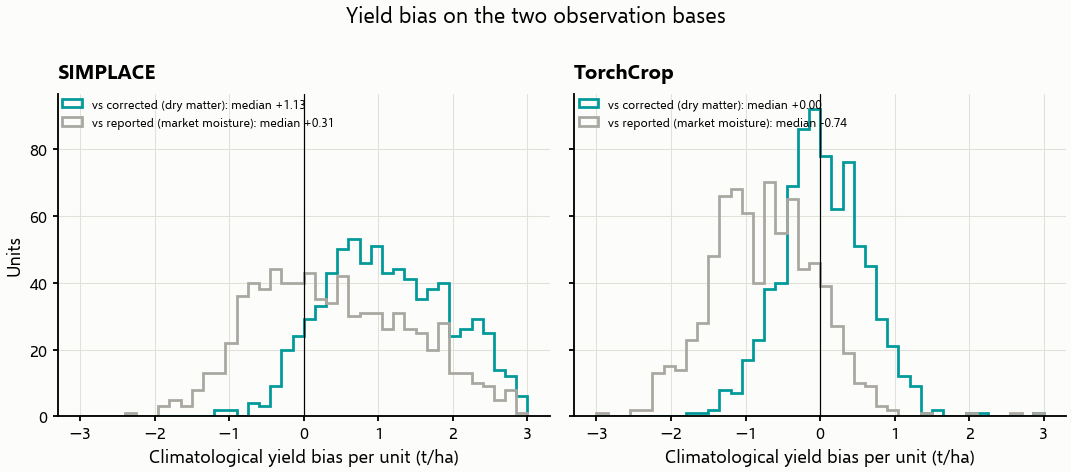

In [10]:
fig, axes = plt.subplots(1, len(MODELS), figsize=(10.0, 4.4), sharex=True, sharey=True)
edges = np.linspace(-3.0, 3.0, 41)
for ax, (model, label) in zip(axes, MODELS.items()):
    block = yield_clim[yield_clim["model"] == model]
    for col, name, colour in (("obs", "vs corrected (dry matter)", PALETTE["torchcrop"]),
                              ("obs_reported", "vs reported (market moisture)", PALETTE["simplace"])):
        diff = block["sim"] - block[col]
        ax.hist(diff, bins=edges, histtype="step", lw=1.8, color=colour,
                label=f"{name}: median {diff.median():+.2f}")
    ax.axvline(0.0, color="black", lw=0.8)
    ax.set_title(label, loc="left", fontweight="bold")
    ax.set_xlabel("Climatological yield bias per unit (t/ha)")
    ax.legend(frameon=False, loc="upper left", fontsize=8)
axes[0].set_ylabel("Units")
fig.suptitle("Yield bias on the two observation bases", y=0.995)
fig.tight_layout()
save(fig, "yield_moisture_basis", FIGURES)

### Poster: grain-yield climatology

The yield maps above, sized for **one column of the two-column TorchCrop
poster** (7.8 in wide). Three maps, one shared colour bar; the bias maps are
replaced by what they were for:

* **Inset histogram**: the spatial distribution of unit means, the bars in the
  map's own colour steps. Model panels overlay the **observed** distribution as
  a black outline, so too much or too little spatial spread shows at a glance.
* **Metrics** (model panels), over the units both sides have:
  **bias**, the mean of model − observed; **r**, the spatial pattern
  correlation; **σ ratio**, model over observed spatial standard deviation
  (> 1: regional contrasts exaggerated).

Saved as `poster_climatology_yield.{png,pdf,svg}`.

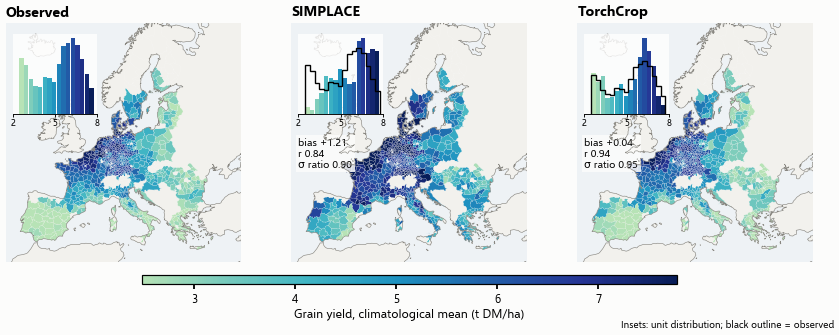

In [11]:
from matplotlib.cm import ScalarMappable
from matplotlib.colors import LinearSegmentedColormap, Normalize

from cropmodelling4eu.evaluation.plots import _basemap

# Continuous version of CLIM_CMAP's range (YlGnBu from 0.28), for the poster only.
POSTER_CMAP = LinearSegmentedColormap.from_list(
    "YlGnBu_poster", plt.get_cmap("YlGnBu")(np.linspace(0.28, 1.0, 256)))
POSTER_BINS = 16
POSTER_TEXT = {"font.size": 8.1, "axes.titlesize": 9.4, "axes.titlepad": 4.0,
               "xtick.labelsize": 7.5, "axes.labelsize": 8.1}


def spatial_metrics(sim: pd.Series, obs: pd.Series) -> dict[str, float]:
    """Bias, pattern correlation and spatial-spread ratio over shared units."""
    both = pd.concat({"sim": sim, "obs": obs}, axis=1).dropna()
    return {"bias": float((both["sim"] - both["obs"]).mean()),
            "r": float(both["sim"].corr(both["obs"])),
            "sd_ratio": float(both["sim"].std() / both["obs"].std())}


def spread_inset(ax, values: pd.Series, edges: np.ndarray, reference: pd.Series | None):
    # Histogram over the empty Atlantic corner, bars in the map's colour steps.
    inset = ax.inset_axes((0.03, 0.62, 0.36, 0.33))
    counts, _ = np.histogram(values.dropna(), bins=edges)
    centres = (edges[:-1] + edges[1:]) / 2
    inset.bar(centres, counts, width=np.diff(edges) * 0.92,
              color=POSTER_CMAP(np.linspace(0, 1, len(centres))), linewidth=0)
    if reference is not None:
        ref, _ = np.histogram(reference.dropna(), bins=edges)
        inset.stairs(ref, edges, color="black", linewidth=0.9)
    inset.set_facecolor((1, 1, 1, 0.8))
    inset.set_yticks([])
    inset.set_xticks(edges[[0, len(edges) // 2, -1]].round(0))
    inset.tick_params(axis="x", labelsize=6, length=2, width=0.6, pad=1)
    inset.grid(False)
    for side in ("top", "right", "left"):
        inset.spines[side].set_visible(False)
    inset.spines["bottom"].set_linewidth(0.6)


def poster_climatology(target: prod.Target):
    clim = climatology[climatology["target"] == target.key]
    observed = clim.drop_duplicates("adm_id").set_index("adm_id")["obs"]
    sim = {m: clim[clim["model"] == m].set_index("adm_id")["sim"] for m in MODELS}
    lo, hi = np.nanpercentile(np.r_[observed, clim["sim"]], [5, 95])
    edges = np.linspace(lo, hi, POSTER_BINS + 1)
    norm = Normalize(lo, hi)
    mapped = polygons.to_crs(EUROPE_PROJECTION.proj4_init)
    unit = "DOY" if target.circular else target.unit
    with plt.rc_context(POSTER_TEXT):
        fig = plt.figure(figsize=(7.8, 3.05))
        grid = fig.add_gridspec(2, 3, height_ratios=(1, 0.04), wspace=0.03, hspace=0.1,
                                left=0.005, right=0.995, top=0.92, bottom=0.14)
        panels = [("Observed", observed, None), *[(MODELS[m], sim[m], observed) for m in MODELS]]
        for col, (title, values, reference) in enumerate(panels):
            ax = fig.add_subplot(grid[0, col], projection=EUROPE_PROJECTION)
            # Drawn here rather than with country_choropleth, which always adds
            # its own colour bar: the three maps share the one below.
            _basemap(ax, PALETTE)
            ax.grid(False)
            frame = mapped.assign(value=mapped["adm_id"].map(values))
            frame.plot(ax=ax, column="value", cmap=POSTER_CMAP, norm=norm,
                       edgecolor=PALETTE["surface"], linewidth=0.08, zorder=2,
                       missing_kwds={"color": PALETTE["land"], "edgecolor": PALETTE["surface"],
                                     "linewidth": 0.08})
            ax.set_title(title, loc="left", fontweight="bold")
            spread_inset(ax, values, edges, reference)
            if reference is not None:
                m = spatial_metrics(values, reference)
                # Under the inset, over the UK and Ireland, which have no units.
                ax.text(0.03, 0.52, f"bias {m['bias']:+.2f}\nr {m['r']:.2f}\n"
                        f"σ ratio {m['sd_ratio']:.2f}", transform=ax.transAxes,
                        ha="left", va="top", fontsize=7, color="black", linespacing=1.15,
                        bbox={"facecolor": PALETTE["surface"], "edgecolor": "none",
                              "alpha": 0.85, "pad": 1.5})
        cax = fig.add_subplot(grid[1, :].subgridspec(1, 3, width_ratios=(0.2, 1, 0.2))[0, 1])
        bar = fig.colorbar(ScalarMappable(norm, POSTER_CMAP),
                           cax=cax, orientation="horizontal")
        bar.set_label(f"{target.label}, climatological mean ({unit})", labelpad=2)
        bar.outline.set_linewidth(0.8)
        fig.text(0.995, 0.005, "Insets: unit distribution; black outline = observed",
                 ha="right", va="bottom", fontsize=6.5)
    for ext in ("png", "pdf", "svg"):
        fig.savefig(FIGURES / f"poster_climatology_{target.key}.{ext}", dpi=300,
                    bbox_inches="tight")
    return fig


poster_climatology(next(t for t in prod.TARGETS if t.key == "yield"));

## 3. Per-unit scores

In [12]:
units = prod.unit_scores(paired, min_years=MIN_YEARS)
units.to_csv(TABLES / "unit_scores.csv", index=False)
(units.groupby(["target", "model"])[["n", "bias", "rmse", "pearson_r2", "ia", "mnb"]]
 .median().round(2).rename(columns=lambda c: "R²" if c == "pearson_r2" else c.upper()))

N   BIAS   RMSE    R²    IA    MNB
target        model                                           
emergence     simplace    8.0 -11.06  19.66  0.09  0.38    NaN
              torchcrop   8.0 -11.51  19.84  0.09  0.37    NaN
harvest       simplace    8.0  -6.68   8.29  0.56  0.60    NaN
              torchcrop   8.0  -1.80   5.41  0.57  0.74    NaN
season_length simplace    8.0   4.24  17.40  0.23  0.46   2.02
              torchcrop   8.0   8.66  19.10  0.22  0.46   3.52
yield         simplace   21.0   1.13   1.44  0.12  0.41  22.27
              torchcrop  21.0   0.00   0.74  0.18  0.55   1.18

## 4. Maps

One figure per target: rows are the metrics, columns the two models, and
**every row shares one colour scale** so the models can be read against each
other. Units in the background colour have fewer than `MIN_YEARS` paired
seasons or no reference at all. RMSE, R² and IA use the sequential ramp; MNB and
bias the diverging one, centred on zero (red = model high or late).

In [13]:
#: Metrics bounded to [0, 1], drawn on a fixed scale.
UNIT_INTERVAL = {"pearson_r2", "ia"}


def metric_rows(target: prod.Target) -> list[tuple[str, str, bool]]:
    """``(column, label, diverging)`` for the four map rows of one target."""
    third = ("bias", f"Bias ({target.unit})", True) if target.circular else (
        "mnb", "MNB (%)", True)
    return [("rmse", f"RMSE ({target.unit})", False), ("pearson_r2", "R²", False),
            ("ia", "IA", False), third]


def target_maps(target: prod.Target):
    scores = units[units["target"] == target.key]
    rows = metric_rows(target)
    fig, axes = plt.subplots(len(rows), len(MODELS), figsize=(9.0, 4.5 * len(rows)),
                             subplot_kw={"projection": EUROPE_PROJECTION})
    for r, (col, label, diverging) in enumerate(rows):
        limit = _limit(scores[col])
        for c, (model, model_label) in enumerate(MODELS.items()):
            values = scores[scores["model"] == model].set_index("adm_id")[col]
            if col in UNIT_INTERVAL:
                kwargs = {"vmin": 0.0, "vmax": 1.0}
            elif diverging:
                kwargs = {"vmax": limit}
            else:
                kwargs = {"vmin": 0.0, "vmax": limit}
            country_choropleth(
                polygons, values, key_col="adm_id", diverging=diverging,
                cmap=None if diverging else SEQUENTIAL_CMAP,
                title=f"{model_label} — {label}", cbar_label=label,
                linewidth=0.15, ax=axes[r, c], **kwargs,
            )
            median = float(values.median())
            axes[r, c].text(0.03, 0.03, f"median {median:.2f}", transform=axes[r, c].transAxes,
                            fontsize=10, color="black",
                            bbox={"facecolor": PALETTE["surface"], "edgecolor": "none",
                                  "alpha": 0.85, "pad": 2})
    fig.suptitle(f"{target.label} vs {'dry-matter CyBench' if target.key == 'yield' else 'corrected CLMS'}"
                 f" — per unit, ≥ {MIN_YEARS} seasons", y=0.995)
    fig.tight_layout()
    save(fig, f"map_{target.key}", FIGURES)
    return fig

### Yield

Yield MNB divides by each observed season, so a unit with a handful of very low CyBench years reads far more positive than its bias in t/ha suggests.

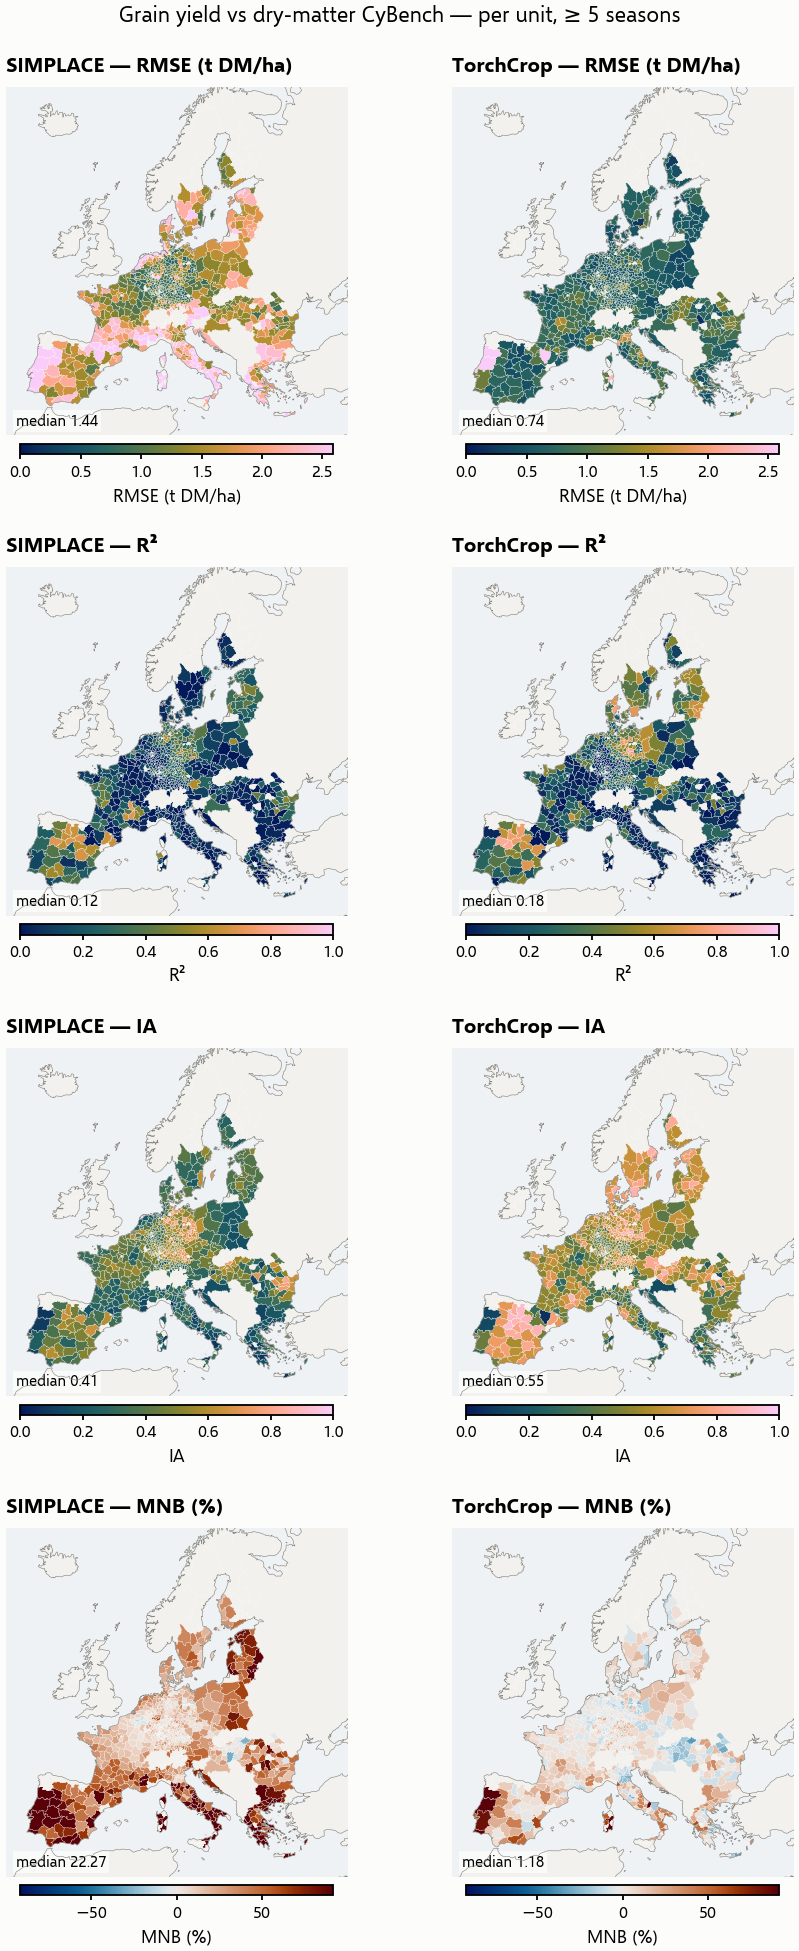

In [14]:
target_maps(next(t for t in prod.TARGETS if t.key == 'yield'));

### Emergence

CLMS emergence carries almost no interannual signal (anomaly r 0.11 against PEP725), so a low per-unit IA here says more about the reference than the model; RMSE and bias are the informative rows.

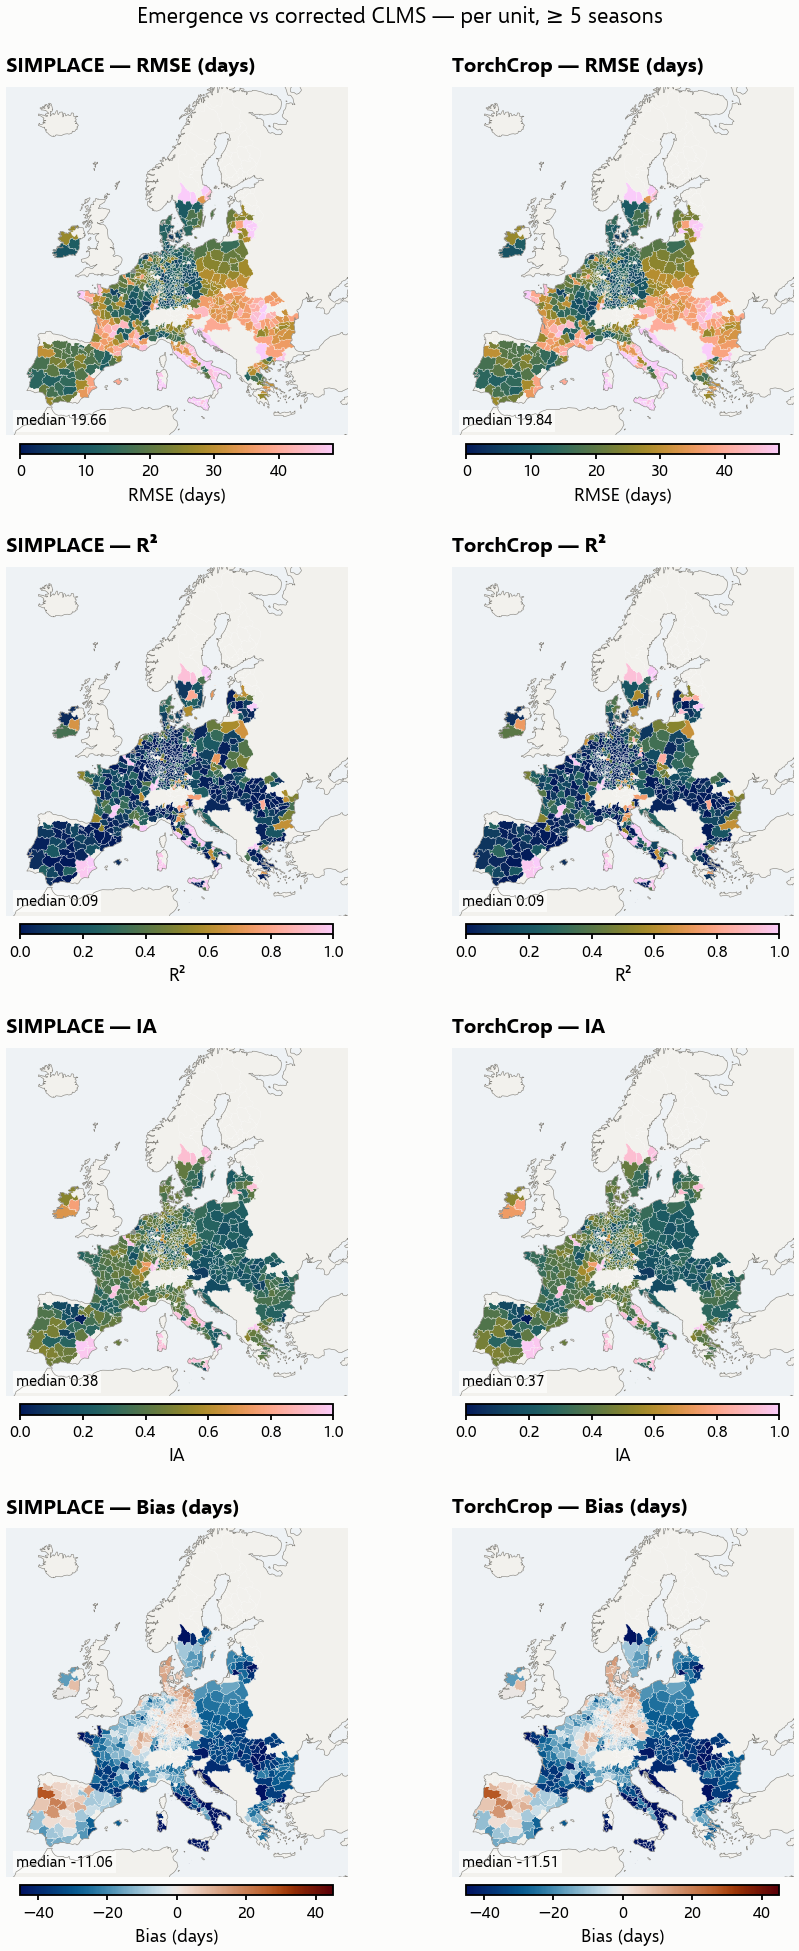

In [15]:
target_maps(next(t for t in prod.TARGETS if t.key == 'emergence'));

### Harvest

The cleanest pairing: CLMS harvest keeps real interannual skill, and the +18.7 d correction puts it on the ground scale.

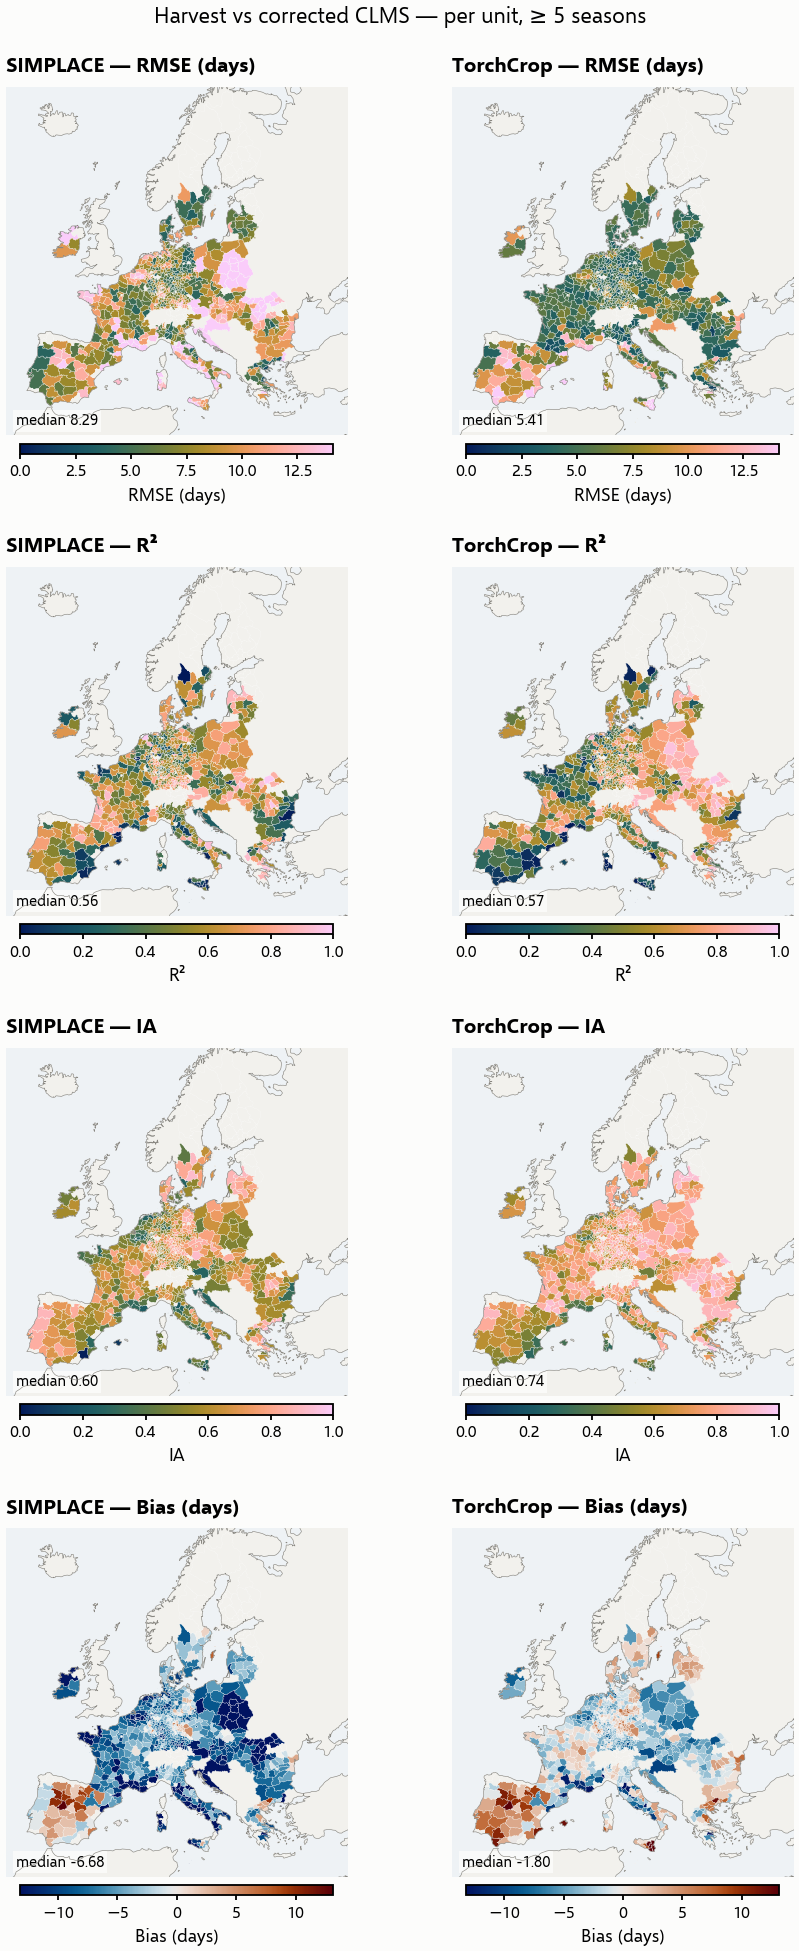

In [16]:
target_maps(next(t for t in prod.TARGETS if t.key == 'harvest'));

### Season length

Bias here is bias(harvest) − bias(emergence), so it closes against the two maps above.

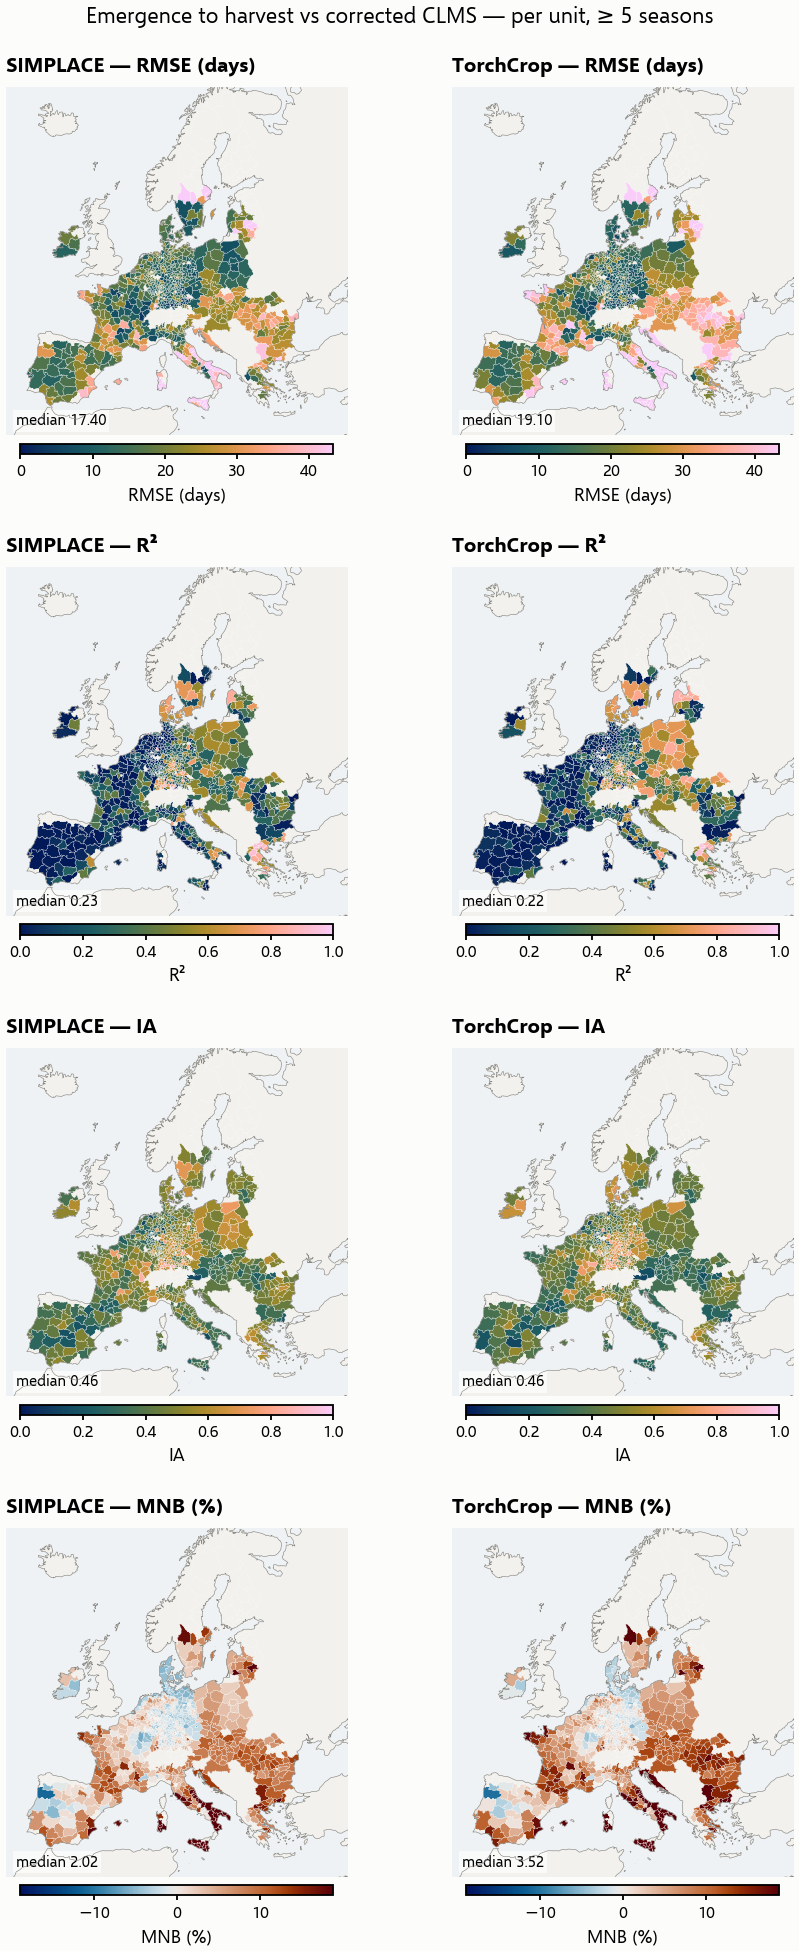

In [17]:
target_maps(next(t for t in prod.TARGETS if t.key == 'season_length'));

## 5. Time series of spatial skill

The maps score each unit over its seasons; this scores **each season over its
units**. For every year, all paired units form one sample, so RMSE, R², IA and
MNB say how well that year's map was reproduced: a dip in R² or IA marks a season whose
spatial pattern the model got wrong, and a step in MNB a year it got wrong
everywhere at once. The top row is the equal-weight mean over the paired units,
observed against both models (dates as circular means). The set of units
changes from year to year — CyBench 2021 has 278 reporting units against ~700
in earlier years — so a step in the mean can be a change of composition rather
than of season; the error metrics are paired and do not carry that artefact.

Shaded years are temporally held out: no unit-year of that season was in the
calibration's `train` split. A season in which only spatially held-out units are
`test` is not shaded, since most of its units were still fitted.

In [18]:
yearly = prod.yearly_scores(paired)
yearly.to_csv(TABLES / "yearly_scores.csv", index=False)
# The poster's encoding: SIMPLACE a thick grey line (the reference
# implementation), TorchCrop teal with circles, observed black.
COLOURS = {"simplace": PALETTE["simplace"], "torchcrop": PALETTE["torchcrop"]}
LINES = {"simplace": {"lw": 2.6, "marker": None},
         "torchcrop": {"lw": 1.4, "marker": "o", "ms": 3.5}}


def target_timeseries(target: prod.Target):
    scores = yearly[yearly["target"] == target.key].sort_values("year")
    rows = [("obs_mean", f"Mean ({target.unit})", None), *metric_rows(target)]
    fig, axes = plt.subplots(len(rows), 1, figsize=(8.0, 1.9 * len(rows)), sharex=True)
    held = scores.loc[scores["held_out"], "year"].unique()
    for ax, (col, label, diverging) in zip(axes, rows):
        for year in held:
            ax.axvspan(year - 0.5, year + 0.5, color=PALETTE["grid"], zorder=0, lw=0)
        if col == "obs_mean":
            obs = scores.drop_duplicates("year")
            ax.plot(obs["year"], obs["obs_mean"], color="black", marker="s",
                    ms=3, lw=1.4, label="observed", zorder=4)
            for model, model_label in MODELS.items():
                block = scores[scores["model"] == model]
                ax.plot(block["year"], block["sim_mean"], color=COLOURS[model],
                        label=model_label, zorder=3, **LINES[model])
            ax.legend(frameon=False, ncols=3, loc="best")
        else:
            for model, model_label in MODELS.items():
                block = scores[scores["model"] == model]
                ax.plot(block["year"], block[col], color=COLOURS[model], label=model_label,
                        zorder=3, **LINES[model])
            if diverging:
                ax.axhline(0.0, color="black", lw=0.8, zorder=1)
            if col in UNIT_INTERVAL:
                ax.set_ylim(0.0, 1.0)
        ax.set_ylabel(label)
    axes[-1].set_xlabel("Harvest year")
    axes[-1].xaxis.get_major_locator().set_params(integer=True)
    fig.suptitle(f"{target.label} — spatial skill per season "
                 f"(units per year: {int(scores['n'].median())} median)", y=0.995)
    fig.tight_layout()
    save(fig, f"timeseries_{target.key}", FIGURES)
    return fig

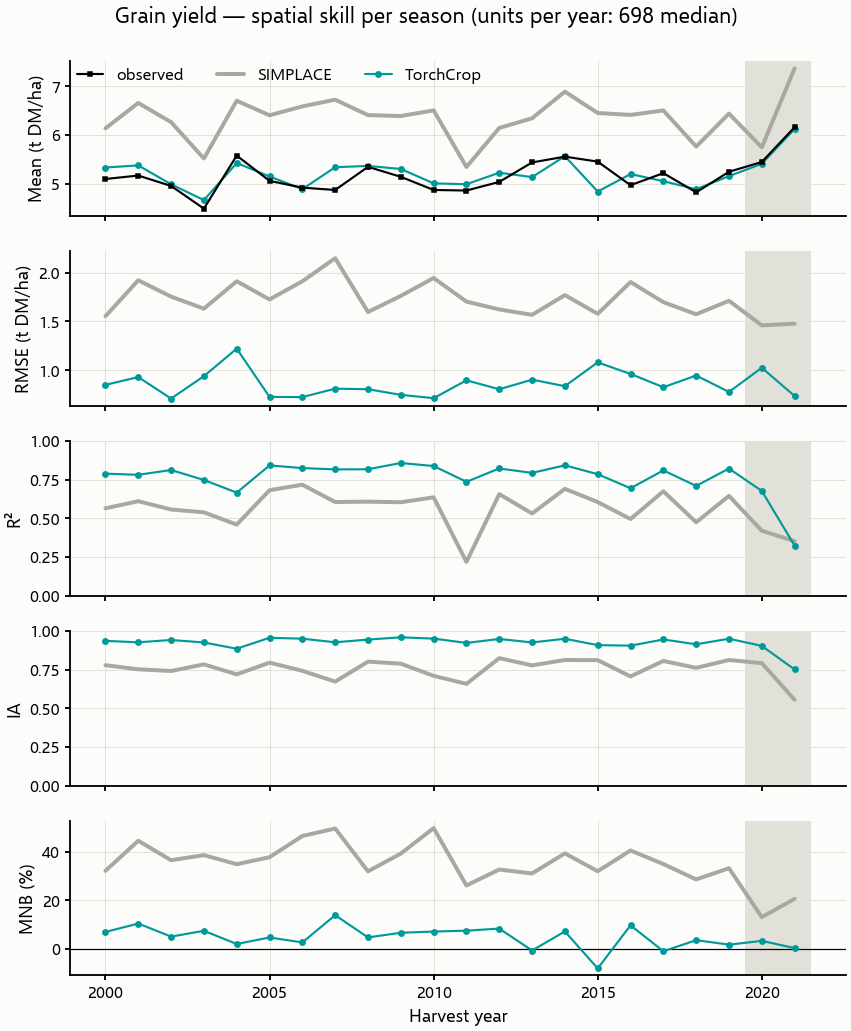

In [19]:
target_timeseries(next(t for t in prod.TARGETS if t.key == 'yield'));

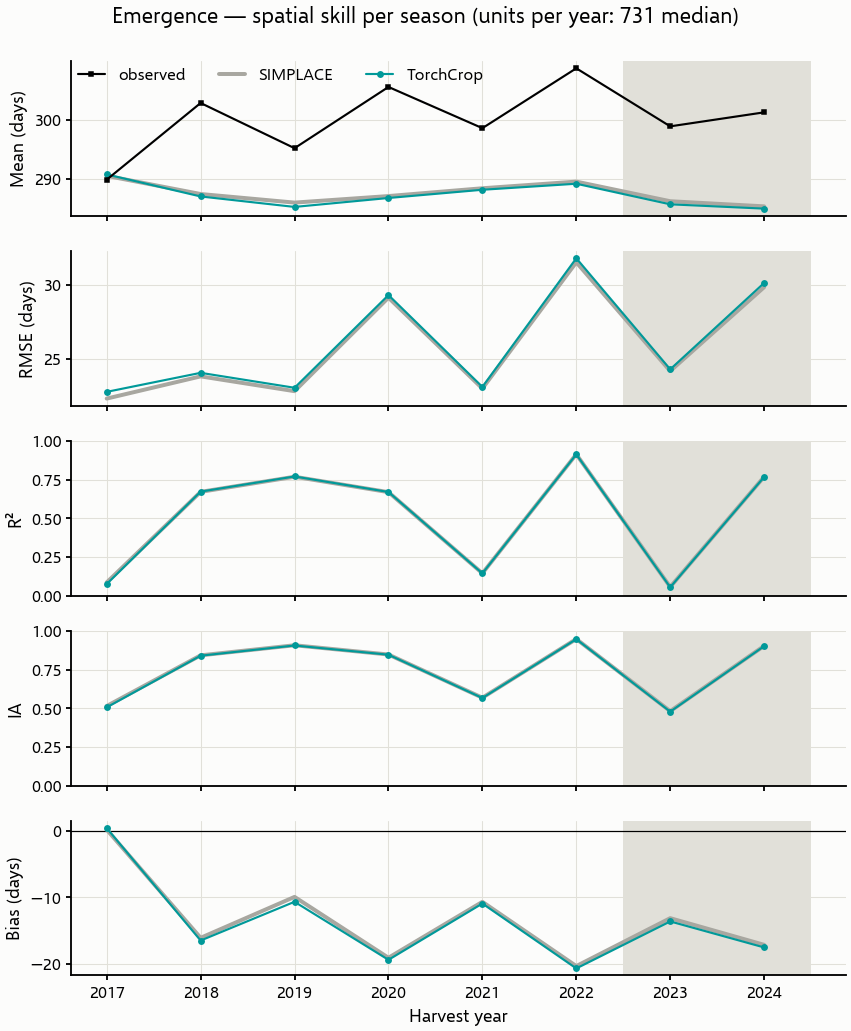

In [20]:
target_timeseries(next(t for t in prod.TARGETS if t.key == 'emergence'));

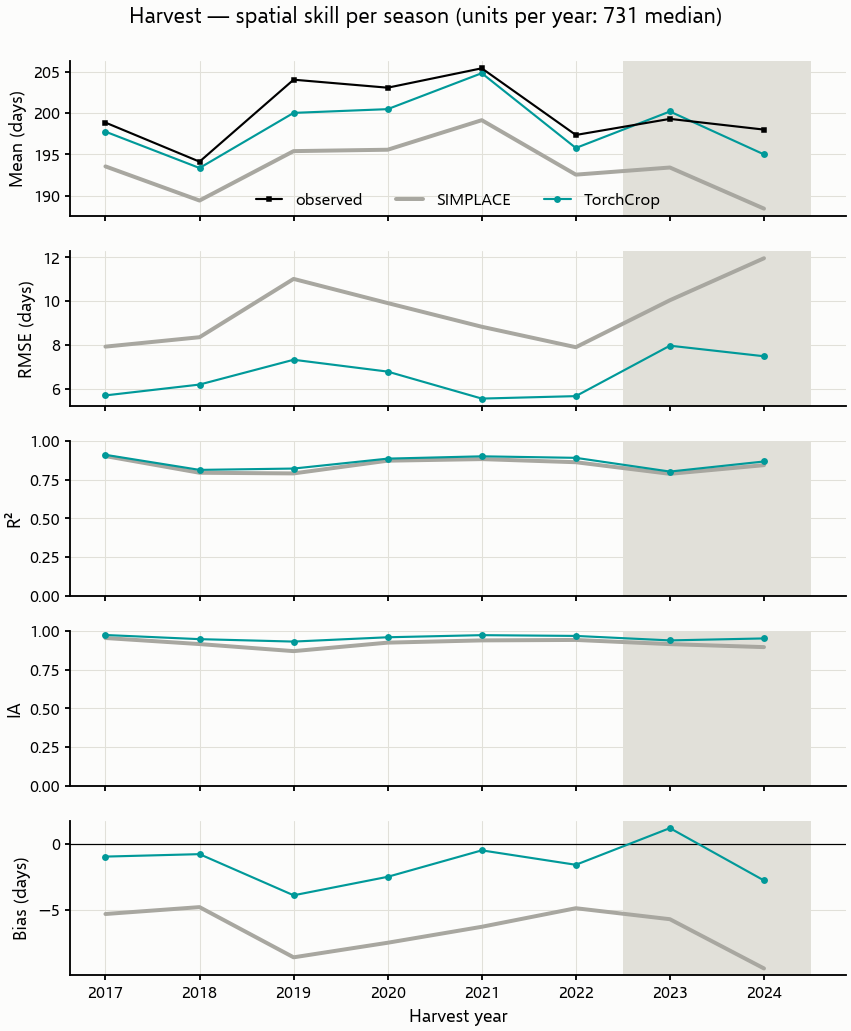

In [21]:
target_timeseries(next(t for t in prod.TARGETS if t.key == 'harvest'));

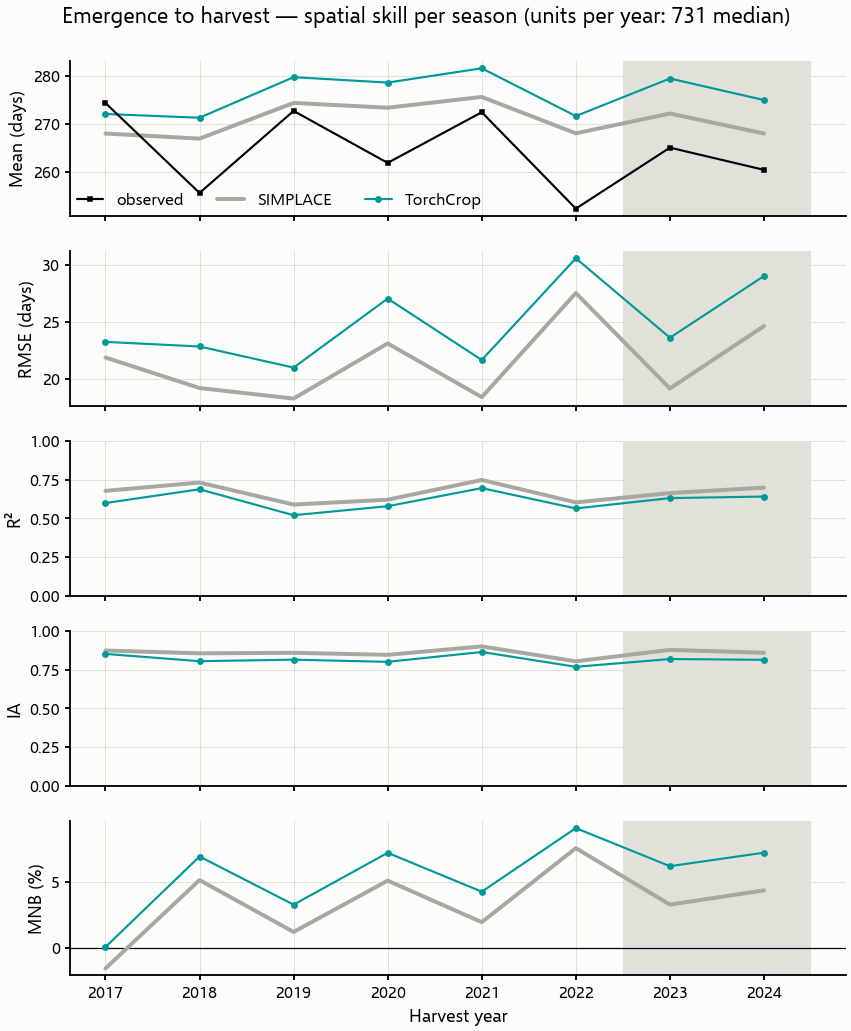

In [22]:
target_timeseries(next(t for t in prod.TARGETS if t.key == 'season_length'));

## 6. Pooled scores by calibration split

Every unit-year pooled. `train` is what the parameters were fitted on;
`val`/`test` are the held-out years and units. A pooled R² or IA includes the
between-unit spread — getting the north-to-south gradient right — so it reads
well above the per-unit medians in §3, which only see each unit's own seasons.

In [23]:
pooled = prod.pooled_scores(paired)
pooled.to_csv(TABLES / "pooled_scores.csv", index=False)
order = {"all": 0, "train": 1, "val": 2, "test": 3, "unused": 4}
(pooled.assign(_o=pooled["split"].map(order)).sort_values(["target", "model", "_o"])
 .drop(columns="_o").set_index(["target", "model", "split"]).round(2)
 .rename(columns=lambda c: "R²" if c == "pearson_r2" else c.upper()))

N   BIAS   RMSE    R²    IA    MNB
target        model     split                                           
emergence     simplace  all      5811.0 -13.64  26.19  0.71  0.89    NaN
                        train    3591.0 -13.65  26.26  0.74  0.90    NaN
                        val       666.0 -13.37  23.95  0.07  0.50    NaN
                        test     1554.0 -13.75  26.94  0.70  0.88    NaN
              torchcrop all      5811.0 -14.00  26.42  0.71  0.88    NaN
                        train    3591.0 -13.97  26.50  0.74  0.90    NaN
                        val       666.0 -13.83  24.06  0.07  0.49    NaN
                        test     1554.0 -14.13  27.20  0.70  0.88    NaN
harvest       simplace  all      5811.0  -6.56   9.65  0.84  0.92    NaN
                        train    3591.0  -6.41   9.20  0.86  0.93    NaN
                        val       666.0  -5.98  10.20  0.79  0.92    NaN
                        test     1554.0  -7.15  10.39  0.83  0.92    NaN
              torchcrop all      5811.0  -1.45   6.69  0.86  0.96    NaN
                        train    3591.0  -1.89   6.24  0.88  0.96    NaN
                        val       666.0   0.92   7.92  0.81  0.94    NaN
                        test     1554.0  -1.47   7.11  0.85  0.96    NaN
season_length simplace  all      5811.0   6.89  21.79  0.65  0.86   3.50
                        train    3591.0   7.01  21.97  0.63  0.86   3.53
                        val       666.0   7.22  19.04  0.67  0.88   3.28
                        test     1554.0   6.48  22.45  0.68  0.86   3.54
              torchcrop all      5811.0  12.35  25.18  0.60  0.82   5.67
                        train    3591.0  11.84  25.00  0.59  0.82   5.45
                        val       666.0  14.58  23.50  0.64  0.82   6.19
                        test     1554.0  12.54  26.27  0.62  0.82   5.98
yield         simplace  all     14929.0   1.18   1.74  0.55  0.77  35.70
                        train   12161.0   1.23   1.76  0.57  0.77  37.19
                        val       564.0   0.29   1.46  0.42  0.79  13.21
                        test     2197.0   1.14   1.72  0.53  0.76  33.24
                        unused      7.0   1.08   1.23  0.35  0.35  33.18
              torchcrop all     14923.0   0.03   0.88  0.77  0.93   4.93
                        train   12161.0   0.04   0.87  0.77  0.94   5.01
                        val       564.0  -0.05   1.05  0.66  0.90   3.31
                        test     2197.0   0.04   0.85  0.78  0.94   4.93
                        unused      1.0   0.16   0.16   NaN   NaN   5.30

## 7. Sowing date

Under the rule-based solution sowing is a SIMPLACE **output**: the first day
in the cell's SAGE planting window on which a weather rule fires, forced on
the window's last day otherwise. Every other model run inherits it, and not all
of them inherit it from this run:

| Consumer | Table | Built from |
|---|---|---|
| This run's SIMPLACE | `simplace/sowing_from_simplace.csv` | its own simulation, on the per-region calibrated crops |
| This run's torchcrop | `MSWX_SOWING` = `sowing_from_simplace_euval.csv` | the **euval** SIMPLACE run, the table the calibration was fitted on |
| Every CMIP6 torchcrop run | `CMIP6_SOWING` = `sowing_climatology_simplace_euval.csv` | the per-cell median of the euval table, repeated every year 1851–2100 |

All three use the sowing table's convention: the exported SIMPLACE date + 1,
the day the crop starts growing (`simplace.collect.sowing_table`). §7.1 checks
whether the tables agree, §7.2 how the rules use the window, and §7.3 validates
the dates against **PEP725 BBCH 0**, the only ground-observed sowing in the
domain. CLMS has no sowing layer.

In [24]:
import json

from cropmodelling4eu.evaluation.doy import doy_difference, doy_in_window

INPUTS = Path("/data01/FDS/muduchuru/Data/SIMPLACE/cropmodelling4eu_inputs")
SOWING_TABLES = {
    "SIMPLACE (this run)": RUN / "simplace" / "sowing_from_simplace.csv",
    "torchcrop MSWX input": Path(os.environ.get(
        "MSWX_SOWING", INPUTS / "sowing_from_simplace_euval.csv")),
    "CMIP6 input": Path(os.environ.get(
        "CMIP6_SOWING", INPUTS / "sowing_climatology_simplace_euval.csv")),
}
KEYS = ["SimplaceID", "year"]
sowing = {name: pd.read_csv(path, engine="pyarrow") for name, path in SOWING_TABLES.items()}
sp_sow = sowing["SIMPLACE (this run)"]

# The CMIP6 table is one date per cell written out for every year; confirm that
# before treating it as a climatology.
cmip = sowing["CMIP6 input"]
assert cmip.groupby("SimplaceID")["sowing_doy"].nunique().max() == 1, "CMIP6 sowing varies by year"
cmip_clim = cmip.drop_duplicates("SimplaceID").set_index("SimplaceID")["sowing_doy"]


def agreement(a: pd.DataFrame | pd.Series, b: pd.DataFrame | pd.Series, on) -> dict[str, float]:
    """Share identical and the circular difference ``a − b`` over shared keys."""
    both = pd.merge(a, b, on=on, suffixes=("_a", "_b"))
    diff = doy_difference(both["sowing_doy_a"].to_numpy(float), both["sowing_doy_b"].to_numpy(float))
    return {"paired": len(both), "identical %": 100 * float(np.mean(diff == 0)),
            "mean diff (d)": float(diff.mean()), "|diff| p95 (d)": float(np.percentile(np.abs(diff), 95)),
            "min (d)": float(diff.min()), "max (d)": float(diff.max())}


tc_used = runs["torchcrop"][KEYS + ["sowing_doy"]] if "torchcrop" in runs else None
sp_median = sp_sow.groupby("SimplaceID")["sowing_doy"].median().round().rename("sowing_doy")
consistency = pd.DataFrame({
    "this run's torchcrop vs its MSWX input": agreement(tc_used, sowing["torchcrop MSWX input"], KEYS),
    "SIMPLACE (this run) vs torchcrop MSWX input": agreement(sp_sow, sowing["torchcrop MSWX input"], KEYS),
    "SIMPLACE per-cell median vs CMIP6 input": agreement(
        sp_median.reset_index(), cmip_clim.reset_index(), "SimplaceID"),
}).T
consistency.to_csv(TABLES / "sowing_consistency.csv")
print({name: f"{len(t):,} rows, {t['SimplaceID'].nunique():,} cells, "
       f"{t['year'].min()}-{t['year'].max()}" for name, t in sowing.items()})
consistency.round(2)

{'SIMPLACE (this run)': '3,088,059 rows, 68,685 cells, 1979-2024', 'torchcrop MSWX input': '3,070,068 rows, 68,685 cells, 1979-2024', 'CMIP6 input': '17,171,250 rows, 68,685 cells, 1851-2100'}


,paired,identical %,mean diff (d),|diff| p95 (d),min (d),max (d)
this run's torchcrop vs its MSWX input,1711524.0,100.00,0.00,0.0,0.0,0.0
SIMPLACE (this run) vs torchcrop MSWX input,3069254.0,91.74,-0.62,5.0,-70.0,76.0
SIMPLACE per-cell median vs CMIP6 input,68685.0,90.97,-0.45,2.0,-32.0,41.0


### 7.1 Is this run's sowing the CMIP6 sowing?

**Not exactly.** Both torchcrop runs sow on the *euval* SIMPLACE dates, not on
this run's: the first row should read 100 % (torchcrop copies its input), and
the next two measure how far this run's SIMPLACE has moved away from that
input. The weather is the same, so the change has to come through the crop:
the production SIMPLACE runs a different calibrated crop file in each region,
and a rule that reads the simulated soil state would carry that into the date
(not traced to a specific rule yet). The table below shows how the change is
spread across regions. For CMIP6 the gap
is two steps: a per-cell median of euval, held fixed in every year, so CMIP6
sowing does not respond to the CMIP6 forcing at all.

In [25]:
regions = pd.read_parquet(RUN / "simplace" / "simplace_europe.parquet",
                          columns=["SimplaceID", "year", "region", "sowing_forced"])
moved = (sp_sow.merge(sowing["torchcrop MSWX input"], on=KEYS, suffixes=("", "_euval"))
         .merge(regions, on=KEYS)
         .assign(diff=lambda f: doy_difference(f["sowing_doy"].to_numpy(float),
                                               f["sowing_doy_euval"].to_numpy(float))))
(moved.groupby("region")
 .agg(cell_years=("diff", "size"), changed_pct=("diff", lambda d: 100 * (d != 0).mean()),
      mean_diff_d=("diff", "mean"), mean_abs_diff_d=("diff", lambda d: d.abs().mean()))
 .round(2))

,cell_years,changed_pct,mean_diff_d,mean_abs_diff_d
region,,,,
region_01,102240,52.73,-5.02,5.94
region_02,10200,74.47,-8.80,8.91
region_03,424544,25.16,-1.67,1.71
region_04,24024,41.76,-3.48,3.57
region_05,43744,56.20,-5.40,5.43
region_06,52109,0.84,-0.06,0.06
region_07,24615,0.04,-0.00,0.00
region_08,27585,0.44,-0.02,0.02
region_09,2655,23.39,-2.36,2.36


### 7.2 How the rules use the window

The window is the export's SAGE `plant.start`…`plant.end` (`site/site.csv`).
A rule that fires on the opening day sows on table date `start + 2`: one day
for SIMPLACE's `DoSow` latch, one for the table's +1. A large opening-day share
and a per-cell interannual SD near zero mean the date is the window, not a
response to the weather (see the Germany smoke test, 374/390 cell-years).

In [26]:
export_dir = Path(json.loads((RUN / "provenance.json").read_text())["export_dir"])
site = (pd.read_csv(export_dir / "site" / "site.csv")
        .rename(columns={"location": "SimplaceID", "sowing_doy": "sage_sowing_doy"}))
windowed = sp_sow.merge(site[["SimplaceID", "sowing_start_doy", "sowing_end_doy",
                              "sage_sowing_doy", "latitude", "longitude"]], on="SimplaceID")
windowed = windowed.merge(regions[KEYS + ["sowing_forced"]], on=KEYS, how="left")
opening = doy_difference(windowed["sowing_doy"].to_numpy(float),
                         windowed["sowing_start_doy"].to_numpy(float)) == 2
inside = doy_in_window(windowed["sowing_doy"] - 1, windowed["sowing_start_doy"],
                       windowed["sowing_end_doy"])
interannual = sp_sow.groupby("SimplaceID")["sowing_doy"].std()
pd.Series({
    "cell-years": len(windowed),
    "opening day (start + 2) %": 100 * opening.mean(),
    "forced on the last day %": 100 * windowed["sowing_forced"].mean(),
    "outside the window %": 100 * (~inside).mean(),
    "cells with interannual SD < 1 d %": 100 * (interannual < 1).mean(),
    "median per-cell interannual SD (d)": interannual.median(),
}).round(2).to_frame("SIMPLACE (this run)")

,SIMPLACE (this run)
cell-years,3088059.00
opening day (start + 2) %,72.31
forced on the last day %,0.66
outside the window %,2.19
cells with interannual SD < 1 d %,33.34
median per-cell interannual SD (d),2.06


### 7.3 Against PEP725 observed sowing

PEP725 BBCH 0 station-seasons, winter wheat only, each moved onto its harvest
year (`data4simplace.phenology.pep725.station_seasons`: an autumn sowing in Y
belongs to harvest Y+1) and placed in the 10 km cell **containing** the
station. Stations in one cell-season are reduced to their median. Three
candidates are scored on the same cell-seasons:

* **SIMPLACE (this run)**: the simulated date of that season;
* **CMIP6 input**: the fixed per-cell date the CMIP6 runs sow on;
* **SAGE date**: the export's `sowing_doy`, the window midpoint.

*Anomaly r* and the SD ratio use each cell's departures from its own mean, so
they measure the interannual response that a per-cell climatology cannot
have. *Spatial r* correlates per-cell means. Most PEP725 sowing records are
German (DWD), so the pooled row is mostly a German score and the country rows
matter.

In [27]:
from data4simplace.grid import TargetGrid

from cropmodelling4eu.calibration.observations import load_pep725
from cropmodelling4eu.evaluation.config import _env_path
from cropmodelling4eu.evaluation.metrics import agreement_metrics
import yaml

PEP725_ROOT = _env_path("PEP725_ROOT", "/data01/FDS/muduchuru/Data/Agri/PEP725")
grid_cfg = yaml.safe_load((RUN / "config.yaml").read_text())["grid"]
grid = TargetGrid(**{k: grid_cfg[k] for k in
                     ("resolution_deg", "min_lon", "max_lon", "min_lat", "max_lat")})
pep = load_pep725(PEP725_ROOT, grid, years=(int(sp_sow["year"].min()) - 1, int(sp_sow["year"].max())),
                  include_heading=False)
observed_sowing = (pep.dropna(subset=["sowing_doy"])
                   .groupby(["SimplaceID", "harvest_year"])["sowing_doy"].median()
                   .rename("obs").reset_index().rename(columns={"harvest_year": "year"}))

CANDIDATES = {"SIMPLACE (this run)": "sim", "CMIP6 input": "cmip", "SAGE date": "sage"}
sow_pairs = (observed_sowing
             .merge(sp_sow.rename(columns={"sowing_doy": "sim"}), on=KEYS)
             .merge(cmip_clim.rename("cmip").reset_index(), on="SimplaceID")
             .merge(site[["SimplaceID", "sage_sowing_doy"]].rename(columns={"sage_sowing_doy": "sage"}),
                    on="SimplaceID")
             .merge(cell_to_adm[["SimplaceID", "adm_country"]], on="SimplaceID", how="left"))
# Re-express every candidate on the observation's side of New Year, so the
# anomalies and means below are plain arithmetic.
for col in CANDIDATES.values():
    sow_pairs[col] = sow_pairs["obs"] + doy_difference(sow_pairs[col].to_numpy(float),
                                                       sow_pairs["obs"].to_numpy(float))


def sowing_skill(frame: pd.DataFrame) -> pd.DataFrame:
    """Bias/RMSE/IA plus anomaly and spatial correlation, one row per candidate."""
    anomaly = frame.groupby("SimplaceID")[["obs", *CANDIDATES.values()]].transform(lambda s: s - s.mean())
    cells = frame.groupby("SimplaceID")[["obs", *CANDIDATES.values()]].mean()
    rows = {}
    for label, col in CANDIDATES.items():
        scores = agreement_metrics(frame["obs"].to_numpy(), frame[col].to_numpy(), circular=True)
        rows[label] = {
            "n": scores["n"], "cells": frame["SimplaceID"].nunique(),
            "bias (d)": scores["bias"], "RMSE (d)": scores["rmse"],
            "MAE (d)": float((frame[col] - frame["obs"]).abs().mean()), "IA": scores["ia"],
            "anomaly r": anomaly[col].corr(anomaly["obs"]),
            "anomaly SD ratio": anomaly[col].std() / anomaly["obs"].std(),
            "spatial r": cells[col].corr(cells["obs"]),
        }
    return pd.DataFrame(rows).T


skill = sowing_skill(sow_pairs)
skill.to_csv(TABLES / "sowing_pep725_skill.csv")
print(f"PEP725 sowing: {len(observed_sowing):,} cell-seasons on "
      f"{observed_sowing['SimplaceID'].nunique():,} cells; {len(sow_pairs):,} paired with the run")
skill.round(2)

PEP725 sowing: 31,866 cell-seasons on 2,098 cells; 30,310 paired with the run


/home/muduchuru/miniforge3/envs/sdba/lib/python3.10/site-packages/numpy/lib/_function_base_impl.py:3045: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/home/muduchuru/miniforge3/envs/sdba/lib/python3.10/site-packages/numpy/lib/_function_base_impl.py:3046: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


,n,cells,bias (d),RMSE (d),MAE (d),IA,anomaly r,anomaly SD ratio,spatial r
SIMPLACE (this run),30310.0,1981.0,-7.28,14.95,11.65,0.39,0.0,0.04,0.09
CMIP6 input,30310.0,1981.0,-7.29,14.97,11.66,0.39,NaN,0.00,0.09
SAGE date,30310.0,1981.0,9.32,15.47,12.13,0.44,NaN,0.00,0.17


In [28]:
by_country = (sow_pairs.groupby("adm_country")
              .apply(lambda g: pd.Series({
                  "n": len(g), "obs mean": g["obs"].mean(),
                  **{f"{label} bias": (g[col] - g["obs"]).mean() for label, col in CANDIDATES.items()},
              }))
              .sort_values("n", ascending=False))
by_country.to_csv(TABLES / "sowing_pep725_by_country.csv")
by_country.round(1)

/tmp/ipykernel_675945/4021675053.py:2: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: pd.Series({


,n,obs mean,SIMPLACE (this run) bias,CMIP6 input bias,SAGE date bias
adm_country,,,,,
DE,28929.0,280.2,-6.2,-6.2,9.8
AT,515.0,281.4,-30.4,-30.6,-3.8
SK,406.0,273.1,-28.3,-27.7,0.9
BE,140.0,303.3,-28.8,-28.8,-0.8
HR,107.0,291.4,-44.2,-45.4,-17.4
PL,66.0,279.7,-30.7,-30.8,-1.8
CZ,55.0,279.0,-11.0,-11.0,7.8
FR,47.0,279.3,-5.3,-5.3,24.7
HU,26.0,275.3,-29.4,-31.3,-1.3


PosixPath('/data01/FDS/muduchuru/Data/SIMPLACE/cropmodelling4eu/runs/winter_wheat/calibrated/mswx/evaluation/figures/sowing_pep725.png')

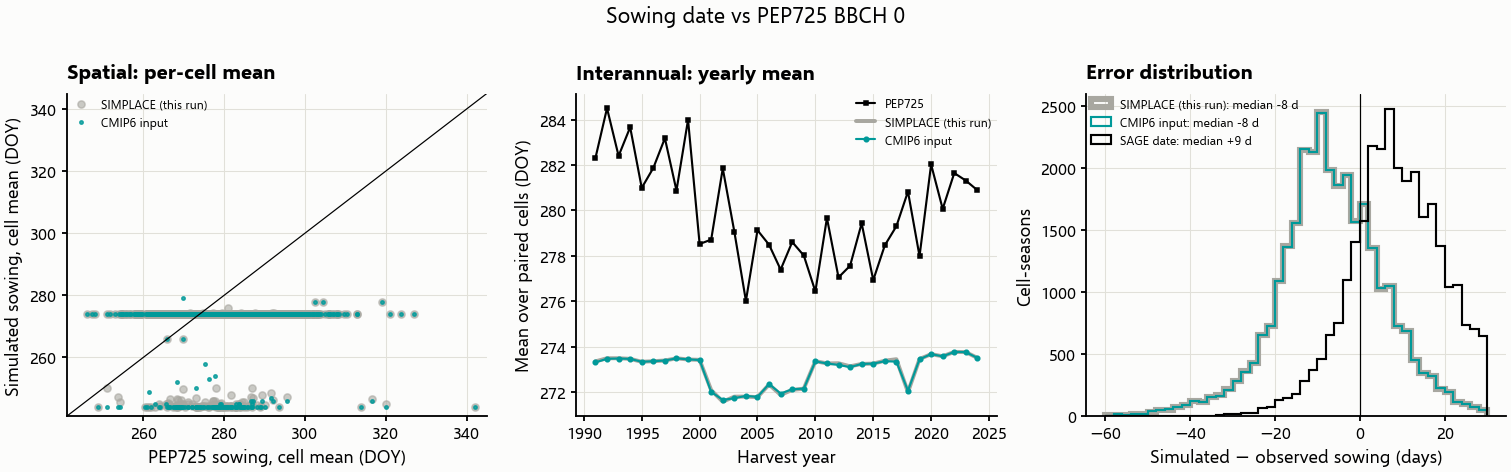

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(14.0, 4.4))
cells = sow_pairs.groupby("SimplaceID")[["obs", "sim", "cmip"]].mean()
lo, hi = np.nanmin(cells.to_numpy()) - 3, np.nanmax(cells.to_numpy()) + 3
ax = axes[0]
# SIMPLACE drawn larger underneath: the two are identical in most cells.
ax.scatter(cells["obs"], cells["sim"], s=22, alpha=0.6, color=PALETTE["simplace"], label="SIMPLACE (this run)")
ax.scatter(cells["obs"], cells["cmip"], s=5, alpha=0.8, color=PALETTE["torchcrop"], label="CMIP6 input")
ax.plot([lo, hi], [lo, hi], color="black", lw=0.8)
ax.set(xlim=(lo, hi), ylim=(lo, hi), xlabel="PEP725 sowing, cell mean (DOY)",
       ylabel="Simulated sowing, cell mean (DOY)", title="Spatial: per-cell mean")
ax.legend(frameon=False, loc="upper left", fontsize=8)

ax = axes[1]
yearly_sow = sow_pairs.groupby("year")[["obs", "sim", "cmip"]].mean()
ax.plot(yearly_sow.index, yearly_sow["obs"], color="black", marker="s", ms=3, lw=1.4, label="PEP725")
ax.plot(yearly_sow.index, yearly_sow["sim"], color=PALETTE["simplace"], lw=2.6, label="SIMPLACE (this run)")
ax.plot(yearly_sow.index, yearly_sow["cmip"], color=PALETTE["torchcrop"], lw=1.4, marker="o", ms=3,
        label="CMIP6 input")
ax.set(xlabel="Harvest year", ylabel="Mean over paired cells (DOY)", title="Interannual: yearly mean")
ax.legend(frameon=False, fontsize=8)

ax = axes[2]
edges = np.arange(-60, 31, 2)
for label, col, colour, lw in (("SIMPLACE (this run)", "sim", PALETTE["simplace"], 4.0),
                               ("CMIP6 input", "cmip", PALETTE["torchcrop"], 1.4),
                               ("SAGE date", "sage", "black", 1.4)):
    diff = sow_pairs[col] - sow_pairs["obs"]
    ax.hist(diff, bins=edges, histtype="step", lw=lw, color=colour,
            label=f"{label}: median {diff.median():+.0f} d")
ax.axvline(0.0, color="black", lw=0.8)
ax.set(xlabel="Simulated − observed sowing (days)", ylabel="Cell-seasons", title="Error distribution")
ax.legend(frameon=False, fontsize=8, loc="upper left")
fig.suptitle("Sowing date vs PEP725 BBCH 0", y=0.995)
fig.tight_layout()
save(fig, "sowing_pep725", FIGURES)

**Reading (calibrated MSWX run, 2026-11-12).** About 30 k PEP725 cell-seasons
on about 2 000 cells, 95 % of them German. SIMPLACE sows **7 d early**
(RMSE 15 d) and is **no better than the fixed CMIP6 date**: the anomaly r is 0.00,
and its interannual SD is 4 % of the observed 8.7 d, because 72 % of
cell-years sow on the window's opening day. Germany is one SAGE unit opening
on DOY 272, so every German cell sows on DOY 274 against an observed 280.
Outside Germany the bias is about −30 d (AT, SK, PL, HU, BE) while the SAGE
midpoint lands within ±4 d there, so the early sowing comes from the
opening-day rule and not from SAGE itself. That is consistent with the
national-block emergence bias in §2. Spatial r is ≈ 0.1 because PEP725 varies
within Germany and the run does not.